In [1]:

# 1. LOAD ENHANCED DATASETS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from IPython.display import display

# Loading the corrected Version 2 datasets
train_df = pd.read_csv(
    "data/enhanced_train_ready_v2.csv"
)

test_df = pd.read_csv(
    "data/enhanced_test_ready_v2.csv"
)

# Identifying survival outcomes and predictors
outcome_columns = [
    "Site_ID", "Lower_Years", "Upper_Years", "Event"
]

predictors = [
    col for col in train_df.columns
    if col not in outcome_columns
]

# Check consistency
assert train_df.columns.equals(test_df.columns)

assert set(train_df["Site_ID"]).isdisjoint(
    set(test_df["Site_ID"])
)

assert len(predictors) == 16

assert np.isfinite(train_df[predictors].to_numpy()).all()
assert np.isfinite(test_df[predictors].to_numpy()).all()

# Verify interval and censoring labels
for df in [train_df, test_df]:
    event = df["Event"].eq(1)
    assert np.isfinite(df.loc[event, "Upper_Years"]).all()
    assert np.isinf(df.loc[~event, "Upper_Years"]).all()
    assert (
        df.loc[event, "Upper_Years"] >
        df.loc[event, "Lower_Years"]
    ).all()

print("ENHANCED DATASETS LOADED")
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))
print("Training events:", train_df["Event"].sum())
print("Testing events:", test_df["Event"].sum())
print("Predictors:", len(predictors))

display(pd.DataFrame({"Predictor": predictors}))


ENHANCED DATASETS LOADED
Training observations: 1618
Testing observations: 399
Training events: 183
Testing events: 39
Predictors: 16


,Predictor
0,IRI_Baseline_Value
1,Rutting_Baseline_Value
2,Asphalt_Thickness_mm
3,Granular_Base_mm
4,Treated_Base_mm
5,Number_of_Layers
6,Has_Granular_Base
7,Has_Treated_Base
8,Prior_MR_Count
9,Prior_Overlay_Count


In [2]:
# 2. PREPARE STATISTICAL MODEL INPUTS

train_scaled = train_df.copy()
test_scaled = test_df.copy()

# Standardise variables with more than two distinct values
scale_columns = [
    col for col in predictors
    if train_df[col].nunique() > 2
]

scaler = StandardScaler()

train_scaled[scale_columns] = scaler.fit_transform(
    train_df[scale_columns]
)

test_scaled[scale_columns] = scaler.transform(
    test_df[scale_columns]
)

print("STATISTICAL MODEL INPUTS READY")
print("Standardised variables:", len(scale_columns))
print("Total predictors:", len(predictors))


STATISTICAL MODEL INPUTS READY
Standardised variables: 10
Total predictors: 16


In [3]:
# 3. FIT WEIBULL AFT AND COX PH

from lifelines import WeibullAFTFitter, CoxPHFitter

# Shared test evaluation for interval-censored outcomes
def calculate_test_nll(model, data, predictors):

    lower = data["Lower_Years"].to_numpy()
    upper = data["Upper_Years"].to_numpy()
    event = data["Event"].to_numpy().astype(bool)

    times = np.unique(
        np.concatenate([lower, upper[event]])
    )

    survival = model.predict_survival_function(
        data[predictors], times=times
    ).to_numpy()

    rows = np.arange(len(data))

    survival_lower = survival[
        np.searchsorted(times, lower), rows
    ]

    probability = survival_lower.copy()

    probability[event] -= survival[
        np.searchsorted(times, upper[event]),
        rows[event]
    ]

    losses = -np.log(
        np.clip(probability, 1e-12, 1.0)
    )

    return (
        losses.mean(),
        losses[event].mean(),
        losses[~event].mean()
    )


# Fit Weibull AFT
weibull_model = WeibullAFTFitter(penalizer=0.01)

weibull_model.fit_interval_censoring(
    train_scaled[["Lower_Years", "Upper_Years"] + predictors],
    lower_bound_col="Lower_Years",
    upper_bound_col="Upper_Years"
)

weibull_scores = calculate_test_nll(
    weibull_model, test_scaled, predictors
)

print("WEIBULL AFT TEST NLL:", round(weibull_scores[0], 4))


# Fit piecewise-baseline Cox PH
event_upper = train_scaled.loc[
    train_scaled["Event"] == 1, "Upper_Years"
]

breakpoints = np.unique(
    np.quantile(event_upper, [0.33, 0.66])
).tolist()

cox_model = CoxPHFitter(
    baseline_estimation_method="piecewise",
    breakpoints=breakpoints,
    penalizer=0.1
)

cox_model.fit_interval_censoring(
    train_scaled[["Lower_Years", "Upper_Years"] + predictors],
    lower_bound_col="Lower_Years",
    upper_bound_col="Upper_Years"
)

cox_scores = calculate_test_nll(
    cox_model, test_scaled, predictors
)

print("COX PH TEST NLL:", round(cox_scores[0], 4))


WEIBULL AFT TEST NLL: 0.4175
COX PH TEST NLL: 0.4262


In [4]:
# 4. FIT XGBOOST SURVIVAL

import xgboost as xgb
from sklearn.model_selection import GroupShuffleSplit

# Prepare XGBoost datasets
def make_dmatrix(data):
    matrix = xgb.DMatrix(data[predictors])
    matrix.set_float_info(
        "label_lower_bound",
        data["Lower_Years"].to_numpy()
    )
    matrix.set_float_info(
        "label_upper_bound",
        data["Upper_Years"].to_numpy()
    )
    return matrix

# Internal validation using training sections only
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

sub_idx, val_idx = next(
    splitter.split(train_df, groups=train_df["Site_ID"])
)

sub_train = train_df.iloc[sub_idx]
validation = train_df.iloc[val_idx]

dsub = make_dmatrix(sub_train)
dval = make_dmatrix(validation)

xgb_params = {
    "objective": "survival:aft",
    "eval_metric": "aft-nloglik",
    "aft_loss_distribution": "normal",
    "aft_loss_distribution_scale": 1.2,
    "tree_method": "hist",
    "learning_rate": 0.05,
    "max_depth": 2,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 1.0,
    "seed": 42
}

# Select boosting rounds using validation data
xgb_validation = xgb.train(
    params=xgb_params,
    dtrain=dsub,
    num_boost_round=500,
    evals=[(dval, "validation")],
    early_stopping_rounds=30,
    verbose_eval=False
)

best_rounds = xgb_validation.best_iteration + 1

# Refit on the full training dataset
dtrain = make_dmatrix(train_df)
dtest = make_dmatrix(test_df)

xgb_model = xgb.train(
    params=xgb_params,
    dtrain=dtrain,
    num_boost_round=best_rounds,
    verbose_eval=False
)

# Preserve the AFT evaluation settings
xgb_model.set_param(xgb_params)

def xgb_nll(data):
    score = xgb_model.eval(
        make_dmatrix(data), name="evaluation"
    )
    return float(score.split(":")[-1])

xgb_scores = (
    xgb_nll(test_df),
    xgb_nll(test_df[test_df["Event"] == 1]),
    xgb_nll(test_df[test_df["Event"] == 0])
)

print("XGBOOST RESULTS")
print("Selected boosting rounds:", best_rounds)
print("Test NLL:", round(xgb_scores[0], 4))


XGBOOST RESULTS
Selected boosting rounds: 91
Test NLL: 0.4454


ENHANCED SURVIVAL MODEL COMPARISON


,Model,Overall_NLL,Event_NLL,Censored_NLL
0,Weibull AFT,0.4175,3.2584,0.1097
1,Cox PH,0.4262,3.3269,0.1120
2,XGBoost Survival,0.4454,3.2749,0.1389


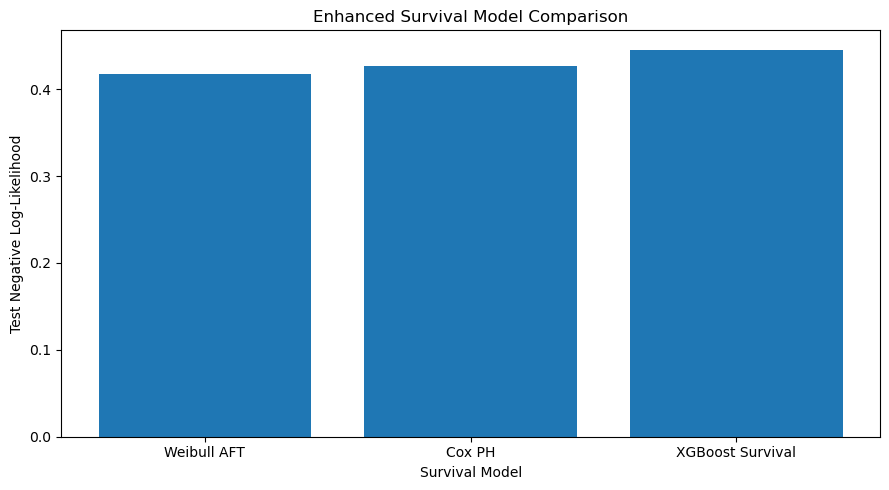

Comparison saved successfully.


In [5]:
# 5. COMPARE ENHANCED SURVIVAL MODELS

comparison = pd.DataFrame({
    "Model": [
        "Weibull AFT",
        "Cox PH",
        "XGBoost Survival"
    ],
    "Overall_NLL": [
        weibull_scores[0],
        cox_scores[0],
        xgb_scores[0]
    ],
    "Event_NLL": [
        weibull_scores[1],
        cox_scores[1],
        xgb_scores[1]
    ],
    "Censored_NLL": [
        weibull_scores[2],
        cox_scores[2],
        xgb_scores[2]
    ]
})

comparison = comparison.sort_values(
    "Overall_NLL"
).reset_index(drop=True)

print("ENHANCED SURVIVAL MODEL COMPARISON")
display(comparison.round(4))

plt.figure(figsize=(9, 5))
plt.bar(
    comparison["Model"],
    comparison["Overall_NLL"]
)
plt.title("Enhanced Survival Model Comparison")
plt.ylabel("Test Negative Log-Likelihood")
plt.xlabel("Survival Model")
plt.tight_layout()
plt.show()

# Save comparison
from pathlib import Path

results_folder = Path("results")
results_folder.mkdir(exist_ok=True)

comparison.to_csv(
    results_folder / "enhanced_model_comparison.csv",
    index=False
)

print("Comparison saved successfully.")


In [6]:
# 6. PAIRED BOOTSTRAP MODEL COMPARISON

from scipy.stats import norm

# Calculate individual observation losses for statistical models
def lifelines_losses(model, data):

    lower = data["Lower_Years"].to_numpy()
    upper = data["Upper_Years"].to_numpy()
    event = data["Event"].to_numpy().astype(bool)

    times = np.unique(
        np.concatenate([lower, upper[event]])
    )

    survival = model.predict_survival_function(
        data[predictors],
        times=times
    ).to_numpy()

    rows = np.arange(len(data))

    probabilities = survival[
        np.searchsorted(times, lower), rows
    ].copy()

    probabilities[event] -= survival[
        np.searchsorted(times, upper[event]),
        rows[event]
    ]

    return -np.log(np.clip(probabilities, 1e-12, 1))


# Calculate individual XGBoost AFT losses
lower = test_df["Lower_Years"].to_numpy()
upper = test_df["Upper_Years"].to_numpy()
event = test_df["Event"].to_numpy().astype(bool)

# Raw prediction represents modelled log survival time
mu = xgb_model.predict(dtest, output_margin=True)

sigma = xgb_params["aft_loss_distribution_scale"]

z_lower = (
    np.log(np.maximum(lower, 1e-300)) - mu
) / sigma

probabilities = norm.sf(z_lower)

z_upper = (
    np.log(upper[event]) - mu[event]
) / sigma

probabilities[event] = (
    norm.cdf(z_upper) - norm.cdf(z_lower[event])
)

xgb_losses = -np.log(
    np.clip(probabilities, 1e-12, 1)
)

# Confirm calculated XGBoost losses agree with its own metric
print("XGBoost calculated NLL:", round(xgb_losses.mean(), 6))
print("XGBoost reported NLL:", round(xgb_scores[0], 6))

assert np.isclose(
    xgb_losses.mean(),
    xgb_scores[0],
    atol=0.0001
)

# Combine all individual test losses
loss_data = pd.DataFrame({
    "Site_ID": test_df["Site_ID"].values,
    "Weibull AFT": lifelines_losses(
        weibull_model, test_scaled
    ),
    "Cox PH": lifelines_losses(
        cox_model, test_scaled
    ),
    "XGBoost": xgb_losses
})

# Prepare pavement-section groups
site_groups = loss_data.groupby("Site_ID").indices
site_ids = np.array(list(site_groups.keys()))

rng = np.random.default_rng(42)

bootstrap_results = []

# Bootstrap physical pavement sections
for i in range(1000):

    sampled_sites = rng.choice(
        site_ids,
        size=len(site_ids),
        replace=True
    )

    selected_rows = np.concatenate([
        site_groups[site] for site in sampled_sites
    ])

    sample = loss_data.iloc[selected_rows]

    bootstrap_results.append({
        "Cox_minus_Weibull": (
            sample["Cox PH"].mean() -
            sample["Weibull AFT"].mean()
        ),
        "XGBoost_minus_Weibull": (
            sample["XGBoost"].mean() -
            sample["Weibull AFT"].mean()
        )
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

# Summarise confidence intervals
print("\n95% BOOTSTRAP CONFIDENCE INTERVALS")

for column in bootstrap_df.columns:

    lower_ci, upper_ci = bootstrap_df[column].quantile(
        [0.025, 0.975]
    )

    print(
        column,
        ":",
        round(lower_ci, 4),
        "to",
        round(upper_ci, 4)
    )

# Export results
bootstrap_df.to_csv(
    results_folder / "enhanced_bootstrap_comparison.csv",
    index=False
)

print("\nBootstrap comparison saved.")


XGBoost calculated NLL: 0.445406
XGBoost reported NLL: 0.445406

95% BOOTSTRAP CONFIDENCE INTERVALS
Cox_minus_Weibull : -0.0031 to 0.0215
XGBoost_minus_Weibull : -0.0068 to 0.0723

Bootstrap comparison saved.


In [7]:
# 7. COMPLETE PAIRWISE MODEL COMPARISON

# Calculate XGBoost versus Cox PH
bootstrap_df["XGBoost_minus_Cox"] = (
    bootstrap_df["XGBoost_minus_Weibull"] -
    bootstrap_df["Cox_minus_Weibull"]
)

# Define all three comparisons
model_pairs = [
    ("Cox PH", "Weibull AFT", "Cox_minus_Weibull"),
    ("XGBoost", "Weibull AFT", "XGBoost_minus_Weibull"),
    ("XGBoost", "Cox PH", "XGBoost_minus_Cox")
]

results = []

for model_a, model_b, column in model_pairs:

    # Observed NLL difference
    difference = (
        loss_data[model_a].mean() -
        loss_data[model_b].mean()
    )

    # Bootstrap confidence interval
    ci_lower, ci_upper = np.quantile(
        bootstrap_df[column],
        [0.025, 0.975]
    )

    results.append({
        "Comparison": f"{model_a} - {model_b}",
        "NLL_Difference": difference,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper,
        "CI_Includes_Zero": ci_lower <= 0 <= ci_upper
    })

# Display results
pairwise_summary = pd.DataFrame(results)

print("FINAL PAIRWISE MODEL COMPARISON")
display(pairwise_summary.round(4))

# Save results
pairwise_summary.to_csv(
    results_folder / "enhanced_pairwise_comparison.csv",
    index=False
)

print("Pairwise comparison saved.")


FINAL PAIRWISE MODEL COMPARISON


,Comparison,NLL_Difference,CI_Lower,CI_Upper,CI_Includes_Zero
0,Cox PH - Weibull AFT,0.0087,-0.0031,0.0215,True
1,XGBoost - Weibull AFT,0.0279,-0.0068,0.0723,True
2,XGBoost - Cox PH,0.0192,-0.0183,0.0674,True


Pairwise comparison saved.


In [8]:

# 8. EXAMINE PREDICTOR EFFECTS AND IMPORTANCE

# WEIBULL AFT: Time ratios
weibull_effects = weibull_model.summary.xs(
    "lambda_", level=0
)[["coef", "exp(coef)", "p"]].copy()

weibull_effects = weibull_effects.rename(
    columns={"exp(coef)": "Time_Ratio"}
).sort_values("p")

print("WEIBULL AFT - PREDICTOR EFFECTS")
display(weibull_effects.round(4))


# COX PH: Hazard ratios
cox_effects = cox_model.summary.copy()

# Retain only predictor coefficients
if isinstance(cox_effects.index, pd.MultiIndex):
    cox_effects = cox_effects[
        cox_effects.index.get_level_values(-1).isin(predictors)
    ]
else:
    cox_effects = cox_effects[
        cox_effects.index.isin(predictors)
    ]

cox_effects = cox_effects[
    ["coef", "exp(coef)", "p"]
].rename(
    columns={"exp(coef)": "Hazard_Ratio"}
).sort_values("p")

print("\nCOX PH - PREDICTOR EFFECTS")
display(cox_effects.round(4))


# XGBOOST: Feature importance
gain = xgb_model.get_score(importance_type="gain")

# Support both named features and f0, f1, etc.
gain = {
    predictors[int(k[1:])]
    if k.startswith("f") and k[1:].isdigit()
    else k: v
    for k, v in gain.items()
}

xgb_importance = pd.DataFrame({
    "Predictor": predictors,
    "Average_Gain": [
        gain.get(col, 0.0) for col in predictors
    ]
}).sort_values("Average_Gain", ascending=False)

print("\nXGBOOST - FEATURE IMPORTANCE")
display(xgb_importance.round(4))


WEIBULL AFT - PREDICTOR EFFECTS


,coef,Time_Ratio,p
covariate,,,
Intercept,3.9971,54.4400,0.0000
Rutting_Baseline_Value,-0.7939,0.4521,0.0000
PAVEMENT_FAMILY_ACUB,0.6099,1.8403,0.0052
Has_Granular_Base,-0.6240,0.5358,0.0091
PAVEMENT_FAMILY_ACTB,-0.6067,0.5451,0.0195
Has_Treated_Base,0.5409,1.7175,0.0593
IRI_Baseline_Value,-0.1289,0.8791,0.0751
Road_Class_Group_Urban,-0.4734,0.6229,0.0997
Prior_MR_Count,0.1328,1.1420,0.3583



COX PH - PREDICTOR EFFECTS


coef  Hazard_Ratio       p
param covariate                                             
beta_ Rutting_Baseline_Value    0.4463        1.5625  0.0000
      IRI_Baseline_Value        0.1228        1.1307  0.0241
      Has_Granular_Base         0.2517        1.2862  0.0526
      PAVEMENT_FAMILY_ACTB      0.2936        1.3412  0.1280
      Has_Treated_Base         -0.1491        0.8615  0.2677
      PAVEMENT_FAMILY_ACUB     -0.1387        0.8705  0.2799
      Prior_Overlay_Count      -0.0663        0.9358  0.2973
      Granular_Base_mm          0.0492        1.0504  0.4155
      Treated_Base_mm          -0.0509        0.9503  0.4307
      Asphalt_Thickness_mm     -0.0396        0.9612  0.4910
      Prior_MR_Count           -0.0455        0.9555  0.4931
      Road_Class_Group_Urban    0.1284        1.1370  0.5572
      Number_of_Layers         -0.0167        0.9834  0.7706
      Lanes_LTPP_Direction     -0.0151        0.9850  0.7812
      Road_Class_Group_Unknown -0.0166        0.9835  0.9381
      Prior_Patching_Count      0.0030        1.0030  0.9641


XGBOOST - FEATURE IMPORTANCE


,Predictor,Average_Gain
1,Rutting_Baseline_Value,18.8990
11,Lanes_LTPP_Direction,8.9273
4,Treated_Base_mm,8.1240
13,PAVEMENT_FAMILY_ACUB,7.8382
5,Number_of_Layers,7.5275
2,Asphalt_Thickness_mm,6.8292
3,Granular_Base_mm,6.5387
8,Prior_MR_Count,6.0299
0,IRI_Baseline_Value,5.4568
9,Prior_Overlay_Count,5.1435


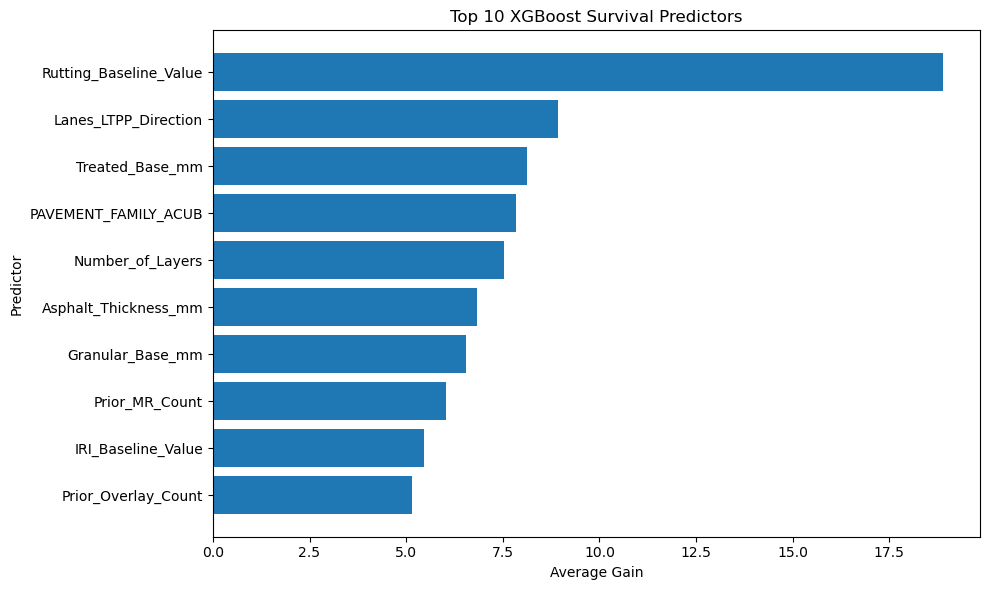

PREDICTOR RESULTS SAVED SUCCESSFULLY
Weibull predictors: 16
Cox PH predictors: 16
XGBoost predictors: 16


In [9]:
# 9. SAVE AND VISUALISE PREDICTOR RESULTS

# Preparation Weibull AFT results
weibull_export = (
    weibull_effects
    .drop(index="Intercept", errors="ignore")
    .reset_index()
    .rename(columns={"covariate": "Predictor"})
)

# Preparaton Cox PH results
cox_export = cox_effects.reset_index()

# Preparation XGBoost results
xgboost_export = xgb_importance.copy()

# Saving the three tables
weibull_export.to_csv(
    results_folder / "enhanced_weibull_effects.csv",
    index=False
)

cox_export.to_csv(
    results_folder / "enhanced_cox_effects.csv",
    index=False
)

xgboost_export.to_csv(
    results_folder / "enhanced_xgboost_importance.csv",
    index=False
)

# Plot the most important XGBoost predictors
top_features = xgboost_export.head(10).sort_values(
    "Average_Gain"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Predictor"],
    top_features["Average_Gain"]
)

plt.title("Top 10 XGBoost Survival Predictors")
plt.xlabel("Average Gain")
plt.ylabel("Predictor")
plt.tight_layout()

plt.savefig(
    results_folder / "enhanced_xgboost_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PREDICTOR RESULTS SAVED SUCCESSFULLY")
print("Weibull predictors:", len(weibull_export))
print("Cox PH predictors:", len(cox_export))
print("XGBoost predictors:", len(xgboost_export))


In [10]:
# 10. SENSITIVITY ANALYSIS: EVENT INTERVAL LENGTH

# Confirm the saved losses match the testing observations
assert len(loss_data) == len(test_df)

assert loss_data["Site_ID"].reset_index(drop=True).equals(
    test_df["Site_ID"].reset_index(drop=True)
)

# Prepare the testing results
sensitivity_data = test_df[
    ["Event", "Lower_Years", "Upper_Years"]
].reset_index(drop=True).copy()

model_names = ["Weibull AFT", "Cox PH", "XGBoost"]

# Adding the calculated losses for each model
for model in model_names:
    sensitivity_data[model] = loss_data[model].to_numpy()

# Calculate event interval lengths
event = sensitivity_data["Event"].eq(1)

sensitivity_data["Interval_Years"] = np.nan

sensitivity_data.loc[event, "Interval_Years"] = (
    sensitivity_data.loc[event, "Upper_Years"] -
    sensitivity_data.loc[event, "Lower_Years"]
)

# Define the evaluation groups
groups = {
    "All test observations": np.ones(
        len(sensitivity_data), dtype=bool
    ),
    "Events within 2 years": (
        event & (sensitivity_data["Interval_Years"] <= 2)
    ),
    "Events longer than 2 years": (
        event & (sensitivity_data["Interval_Years"] > 2)
    ),
    "Right-censored": ~event
}

# Evaluating the models in each group
results = []

for group_name, selected in groups.items():

    subset = sensitivity_data.loc[selected]

    if len(subset) == 0:
        continue

    row = {
        "Group": group_name,
        "Observations": len(subset),
        "Events": int(subset["Event"].sum())
    }

    for model in model_names:
        row[model] = subset[model].mean()

    row["Best_Model"] = min(
        model_names,
        key=lambda name: row[name]
    )

    results.append(row)

#  sensitivity results
sensitivity_summary = pd.DataFrame(results)

print("EVENT INTERVAL SENSITIVITY ANALYSIS")
display(sensitivity_summary.round(4))

# Save the results
sensitivity_summary.to_csv(
    results_folder / "event_interval_sensitivity.csv",
    index=False
)

print("\nSensitivity results saved.")


EVENT INTERVAL SENSITIVITY ANALYSIS


,Group,Observations,Events,Weibull AFT,Cox PH,XGBoost,Best_Model
0,All test observations,399,39,0.4175,0.4262,0.4454,Weibull AFT
1,Events within 2 years,24,24,3.5697,3.7063,3.7212,Weibull AFT
2,Events longer than 2 years,15,15,2.7604,2.7198,2.5609,XGBoost
3,Right-censored,360,0,0.1097,0.1120,0.1389,Weibull AFT



Sensitivity results saved.


In [11]:
# 11. BOOTSTRAP LONG EVENT INTERVALS

# Identify events with intervals longer than two years
long_events = (
    test_df["Event"].eq(1) &
    (
        test_df["Upper_Years"] -
        test_df["Lower_Years"] > 2
    )
)

# Select the corresponding test losses
long_data = loss_data.loc[
    long_events.to_numpy()
].reset_index(drop=True)

print("LONG EVENT INTERVAL ANALYSIS")
print("Observations:", len(long_data))
print("Unique pavement sites:", long_data["Site_ID"].nunique())

# Prepare site-level resampling
site_groups = long_data.groupby("Site_ID").indices
site_ids = list(site_groups.keys())

rng = np.random.default_rng(42)

bootstrap_results = []

# Resample pavement sites 2000 times
for i in range(2000):

    sampled_sites = rng.choice(
        site_ids,
        size=len(site_ids),
        replace=True
    )

    selected_rows = np.concatenate([
        site_groups[site] for site in sampled_sites
    ])

    sample = long_data.iloc[selected_rows]

    bootstrap_results.append({
        "XGBoost_minus_Weibull": (
            sample["XGBoost"].mean() -
            sample["Weibull AFT"].mean()
        ),
        "XGBoost_minus_Cox": (
            sample["XGBoost"].mean() -
            sample["Cox PH"].mean()
        )
    })

long_bootstrap = pd.DataFrame(bootstrap_results)

# Calculating confidence intervals
summary = []

for column in long_bootstrap.columns:

    ci_lower, ci_upper = long_bootstrap[column].quantile(
        [0.025, 0.975]
    )

    summary.append({
        "Comparison": column,
        "Mean_Difference": (
            long_data[
                "XGBoost"
            ].mean() -
            long_data[
                "Weibull AFT" if "Weibull" in column
                else "Cox PH"
            ].mean()
        ),
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper,
        "Includes_Zero": ci_lower <= 0 <= ci_upper
    })

long_bootstrap_summary = pd.DataFrame(summary)

print("\nLONG INTERVAL BOOTSTRAP RESULTS")
display(long_bootstrap_summary.round(4))

# Save results
long_bootstrap_summary.to_csv(
    results_folder / "long_interval_bootstrap_summary.csv",
    index=False
)

print("\nLong interval bootstrap results saved.")


LONG EVENT INTERVAL ANALYSIS
Observations: 15
Unique pavement sites: 15

LONG INTERVAL BOOTSTRAP RESULTS


,Comparison,Mean_Difference,CI_Lower,CI_Upper,Includes_Zero
0,XGBoost_minus_Weibull,-0.1995,-0.4487,0.0372,True
1,XGBoost_minus_Cox,-0.1588,-0.3670,0.0853,True



Long interval bootstrap results saved.


In [12]:
# 12A. DEFINE REPRESENTATIVE PAVEMENT SCENARIOS
# Selecting a test pavement near the median baseline rutting
median_rutting = train_df["Rutting_Baseline_Value"].median()

profile_index = (
    test_df["Rutting_Baseline_Value"] - median_rutting
).abs().idxmin()

base_profile = test_df.loc[
    [profile_index], predictors
].copy()

# Define lower and higher initial rutting conditions
rutting_values = train_df.loc[
    train_df["Rutting_Baseline_Value"] < 10,
    "Rutting_Baseline_Value"
]

low_rutting = rutting_values.quantile(0.25)
high_rutting = rutting_values.quantile(0.75)

assert low_rutting < high_rutting < 10

# Creating two scenarios with identical other predictors
scenarios = {
    "Lower baseline rutting": base_profile.copy(),
    "Higher baseline rutting": base_profile.copy()
}

scenarios["Lower baseline rutting"][
    "Rutting_Baseline_Value"
] = low_rutting

scenarios["Higher baseline rutting"][
    "Rutting_Baseline_Value"
] = high_rutting

print("REPRESENTATIVE PAVEMENT CHARACTERISTICS")

display(base_profile[[
    "IRI_Baseline_Value",
    "Asphalt_Thickness_mm",
    "Granular_Base_mm",
    "Treated_Base_mm",
    "Prior_MR_Count"
]])

print("\nRUTTING SCENARIOS")
print("Lower initial rutting:", round(low_rutting, 2), "mm")
print("Higher initial rutting:", round(high_rutting, 2), "mm")
print("Maintenance threshold: 10 mm")


REPRESENTATIVE PAVEMENT CHARACTERISTICS


,IRI_Baseline_Value,Asphalt_Thickness_mm,Granular_Base_mm,Treated_Base_mm,Prior_MR_Count
8,0.717,167.6,0.0,215.9,1.0



RUTTING SCENARIOS
Lower initial rutting: 2.0 mm
Higher initial rutting: 6.0 mm
Maintenance threshold: 10 mm


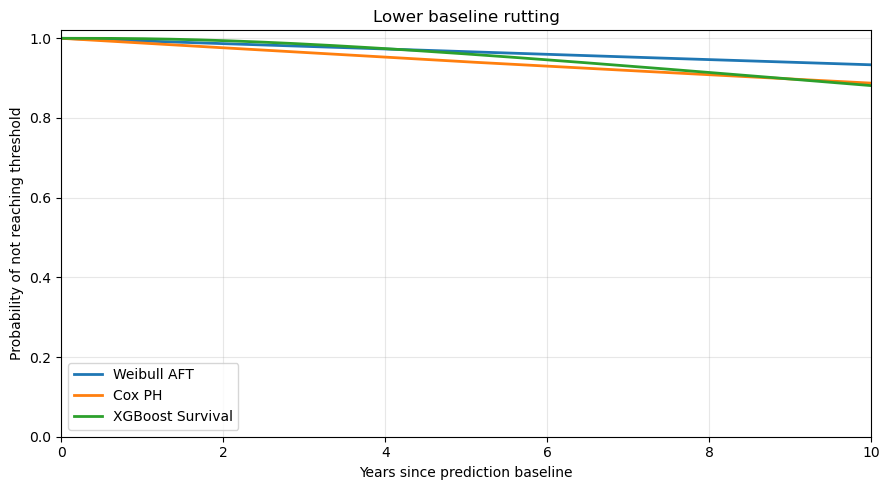

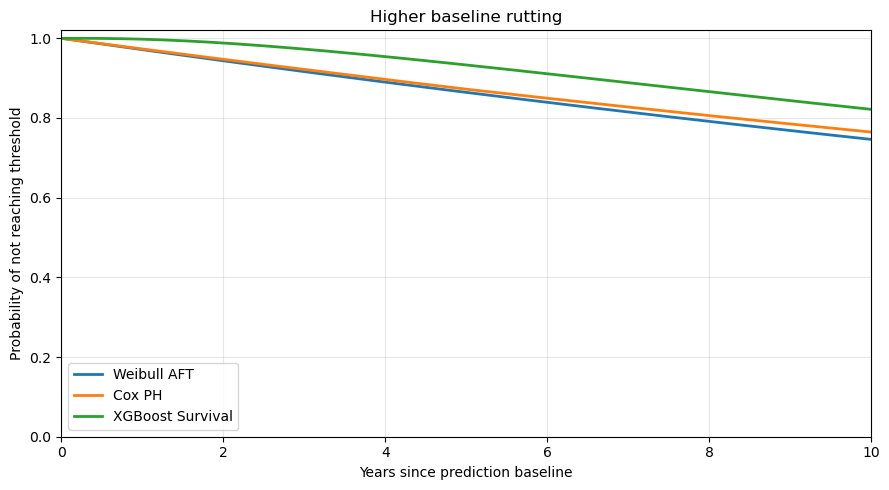

PREDICTED MAINTENANCE-THRESHOLD PROBABILITIES


,Scenario,Model,Years,Threshold_Probability
0,Lower baseline rutting,Weibull AFT,3,0.0203
1,Lower baseline rutting,Weibull AFT,5,0.0337
2,Lower baseline rutting,Cox PH,3,0.0355
3,Lower baseline rutting,Cox PH,5,0.0590
4,Lower baseline rutting,XGBoost Survival,3,0.0145
5,Lower baseline rutting,XGBoost Survival,5,0.0393
6,Higher baseline rutting,Weibull AFT,3,0.0836
7,Higher baseline rutting,Weibull AFT,5,0.1357
8,Higher baseline rutting,Cox PH,3,0.0782
9,Higher baseline rutting,Cox PH,5,0.1277


Prediction horizon: 10.0 years


In [13]:
# 12B. COMPARe PREDICTED PAVEMENT SURVIVAL CURVES

from scipy.stats import norm

# Use a prediction horizon supported by training follow-up
followup = np.where(
    train_df["Event"].eq(1),
    train_df["Upper_Years"],
    train_df["Lower_Years"]
)

horizon = min(10.0, float(np.quantile(followup, 0.90)))
times = np.linspace(0.01, horizon, 150)

prediction_results = []

for scenario_name, profile in scenarios.items():

    # Scale predictors using the original training scaler
    profile_scaled = profile.copy()

    profile_scaled[scale_columns] = scaler.transform(
        profile[scale_columns]
    )

    # Weibull AFT survival predictions
    weibull_survival = (
        weibull_model.predict_survival_function(
            profile_scaled, times=times
        ).iloc[:, 0].to_numpy()
    )

    # Cox PH survival predictions
    cox_survival = (
        cox_model.predict_survival_function(
            profile_scaled, times=times
        ).iloc[:, 0].to_numpy()
    )

    # XGBoost AFT survival predictions
    xgb_profile = xgb.DMatrix(profile[predictors])

    mu = xgb_model.predict(
        xgb_profile, output_margin=True
    )[0]

    sigma = xgb_params["aft_loss_distribution_scale"]

    xgb_survival = norm.sf(
        (np.log(times) - mu) / sigma
    )

    curves = {
        "Weibull AFT": weibull_survival,
        "Cox PH": cox_survival,
        "XGBoost Survival": xgb_survival
    }

    # Plot each pavement scenario separately
    plt.figure(figsize=(9, 5))

    for model_name, survival in curves.items():

        plt.plot(
            times, survival,
            label=model_name,
            linewidth=2
        )

        # Calculating threshold probability at 3 and 5 years
        for year in [3, 5]:

            if year <= horizon:

                probability = 1 - np.interp(
                    year, times, survival
                )

                prediction_results.append({
                    "Scenario": scenario_name,
                    "Model": model_name,
                    "Years": year,
                    "Threshold_Probability": probability
                })

    plt.title(scenario_name)
    plt.xlabel("Years since prediction baseline")
    plt.ylabel("Probability of not reaching threshold")
    plt.ylim(0, 1.02)
    plt.xlim(0, horizon)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Displaying threshold probabilities
probability_summary = pd.DataFrame(prediction_results)

print("PREDICTED MAINTENANCE-THRESHOLD PROBABILITIES")
display(probability_summary.round(4))

print("Prediction horizon:", round(horizon, 2), "years")


FIVE-YEAR THRESHOLD PROBABILITY BY INITIAL RUTTING


,Initial_Rutting_mm,Weibull_AFT_%,Cox_PH_%,XGBoost_%
0,2.0,3.37,5.90,3.93
1,2.5,4.03,6.50,3.93
2,3.0,4.81,7.17,3.80
3,3.5,5.73,7.90,3.80
4,4.0,6.83,8.71,3.80
5,4.5,8.13,9.59,3.80
6,5.0,9.66,10.56,4.94
7,5.5,11.46,11.62,4.94
8,6.0,13.57,12.77,6.69


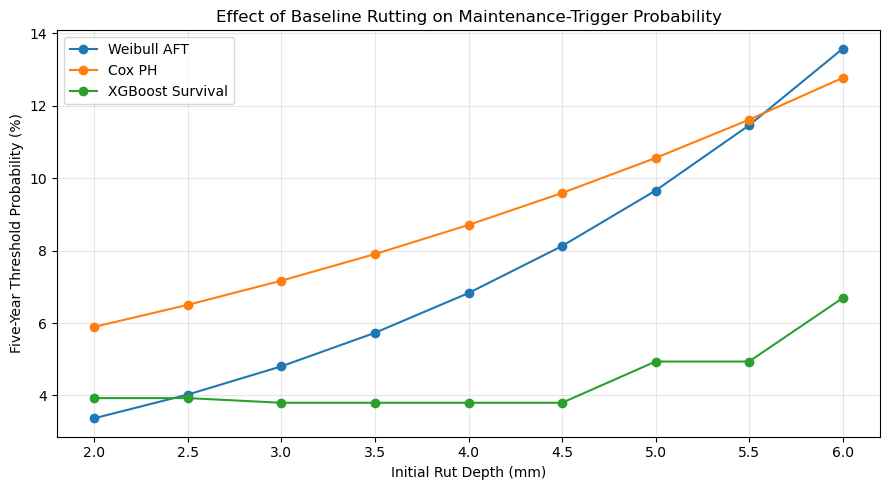

Engineering comparison saved.


In [14]:
# 13. ENGINEERING CONSISTENCY CHECK
# Five-year threshold probability versus initial rutting

# Create a range between the two tested rutting values
rutting_range = np.linspace(
    low_rutting, high_rutting, 9
)

# Repeat the same reference pavement
profiles = pd.concat(
    [base_profile] * len(rutting_range),
    ignore_index=True
)

# Change only initial rutting
profiles["Rutting_Baseline_Value"] = rutting_range

# Prepare inputs for Weibull and Cox PH
profiles_scaled = profiles.copy()

profiles_scaled[scale_columns] = scaler.transform(
    profiles[scale_columns]
)

# Predict five-year survival probabilities
prediction_year = 5.0

weibull_risk = 1 - (
    weibull_model.predict_survival_function(
        profiles_scaled, times=[prediction_year]
    ).iloc[0].to_numpy()
)

cox_risk = 1 - (
    cox_model.predict_survival_function(
        profiles_scaled, times=[prediction_year]
    ).iloc[0].to_numpy()
)

# Predict XGBoost AFT probabilities
dprofiles = xgb.DMatrix(profiles[predictors])

mu = xgb_model.predict(
    dprofiles, output_margin=True
)

sigma = xgb_params["aft_loss_distribution_scale"]

xgb_risk = norm.cdf(
    (np.log(prediction_year) - mu) / sigma
)

# Compare the model predictions
engineering_results = pd.DataFrame({
    "Initial_Rutting_mm": rutting_range,
    "Weibull_AFT_%": weibull_risk * 100,
    "Cox_PH_%": cox_risk * 100,
    "XGBoost_%": xgb_risk * 100
})

print("FIVE-YEAR THRESHOLD PROBABILITY BY INITIAL RUTTING")
display(engineering_results.round(2))

# Plot the predicted relationships
plt.figure(figsize=(9, 5))

for column, label in [
    ("Weibull_AFT_%", "Weibull AFT"),
    ("Cox_PH_%", "Cox PH"),
    ("XGBoost_%", "XGBoost Survival")
]:
    plt.plot(
        engineering_results["Initial_Rutting_mm"],
        engineering_results[column],
        marker="o",
        label=label
    )

plt.xlabel("Initial Rut Depth (mm)")
plt.ylabel("Five-Year Threshold Probability (%)")
plt.title("Effect of Baseline Rutting on Maintenance-Trigger Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_folder / "rutting_engineering_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save numerical results
engineering_results.to_csv(
    results_folder / "rutting_engineering_comparison.csv",
    index=False
)

print("Engineering comparison saved.")


ACTUAL PAVEMENT PROFILE COMPARISON


,Rutting_Group,Observations,Median_Rutting_mm,Weibull_AFT,Cox_PH,XGBoost
0,Group 1,106,2.0,3.21,5.50,5.29
1,Group 2,132,4.0,6.87,8.52,5.27
2,Group 3,97,6.0,14.72,13.76,10.59
3,Group 4,64,7.0,28.92,20.61,40.26


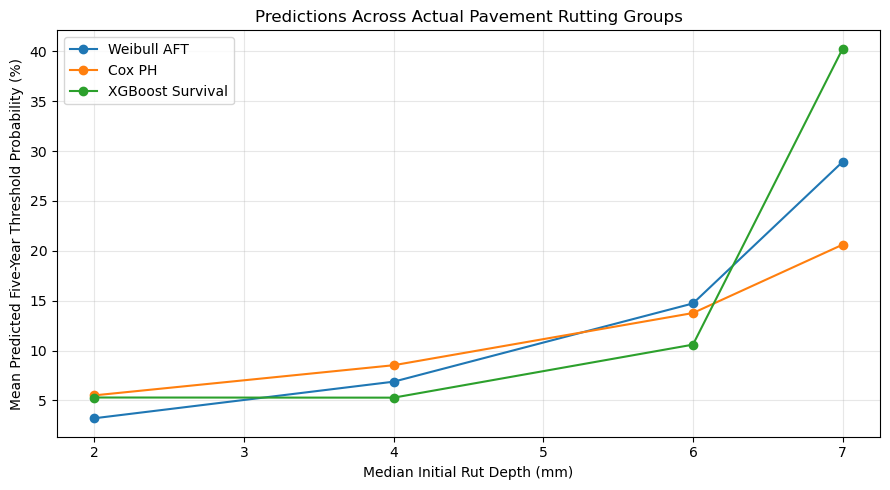

Actual pavement comparison saved.


In [15]:
# 14. ENGINEERING CHECK USING ACTUAL TEST PAVEMENTS

# Prepare actual pavement profiles
test_profiles = test_df[
    ["Site_ID", "Rutting_Baseline_Value"]
].copy()

# Predict five-year threshold probabilities
test_profiles["Weibull_5yr_%"] = 100 * (
    1 - weibull_model.predict_survival_function(
        test_scaled, times=[5.0]
    ).iloc[0].to_numpy()
)

test_profiles["Cox_5yr_%"] = 100 * (
    1 - cox_model.predict_survival_function(
        test_scaled, times=[5.0]
    ).iloc[0].to_numpy()
)

mu_test = xgb_model.predict(
    dtest, output_margin=True
)

test_profiles["XGBoost_5yr_%"] = 100 * norm.cdf(
    (np.log(5.0) - mu_test) /
    xgb_params["aft_loss_distribution_scale"]
)

# Define rutting groups from training-data quartiles
edges = np.unique(
    np.quantile(
        train_df["Rutting_Baseline_Value"],
        [0, 0.25, 0.50, 0.75, 1]
    )
)

assert len(edges) >= 3

edges[0] = -np.inf
edges[-1] = np.inf

labels = [
    f"Group {i+1}"
    for i in range(len(edges) - 1)
]

test_profiles["Rutting_Group"] = pd.cut(
    test_profiles["Rutting_Baseline_Value"],
    bins=edges,
    labels=labels,
    include_lowest=True
)

# Summarise model predictions by rutting group
group_summary = test_profiles.groupby(
    "Rutting_Group", observed=True
).agg(
    Observations=("Site_ID", "size"),
    Median_Rutting_mm=("Rutting_Baseline_Value", "median"),
    Weibull_AFT=("Weibull_5yr_%", "mean"),
    Cox_PH=("Cox_5yr_%", "mean"),
    XGBoost=("XGBoost_5yr_%", "mean")
).reset_index()

print("ACTUAL PAVEMENT PROFILE COMPARISON")
display(group_summary.round(2))

# Visualise predicted probabilities
plt.figure(figsize=(9, 5))

for column, label in [
    ("Weibull_AFT", "Weibull AFT"),
    ("Cox_PH", "Cox PH"),
    ("XGBoost", "XGBoost Survival")
]:
    plt.plot(
        group_summary["Median_Rutting_mm"],
        group_summary[column],
        marker="o",
        label=label
    )

plt.xlabel("Median Initial Rut Depth (mm)")
plt.ylabel("Mean Predicted Five-Year Threshold Probability (%)")
plt.title("Predictions Across Actual Pavement Rutting Groups")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#  results
group_summary.to_csv(
    results_folder / "actual_pavement_rutting_comparison.csv",
    index=False
)

print("Actual pavement comparison saved.")


In [16]:
# 15. CHECK FIVE-YEAR OUTCOME OBSERVABILITY

# Define prediction horizon
year = 5.0

# Retrieve survival outcomes
event = test_df["Event"].eq(1)
lower = test_df["Lower_Years"]
upper = test_df["Upper_Years"]

# Threshold definitely reached by five years
known_event = (
    event &
    (upper <= year)
)

# Threshold definitely not reached by five years
# Includes events occurring after year 5 and
# censored observations followed for at least 5 years
known_no_event = lower >= year

# Classify five-year outcome
five_year_status = np.select(
    [known_event, known_no_event],
    ["Exceeded by 5 years", "No exceedance by 5 years"],
    default="Unknown at 5 years"
)

# Attaching outcomes to the existing pavement groups
five_year_check = test_profiles[
    ["Site_ID", "Rutting_Group"]
].copy()

five_year_check["Five_Year_Status"] = five_year_status

# Summary outcomes
print("FIVE-YEAR OUTCOME VERIFICATION")

display(
    five_year_check["Five_Year_Status"].value_counts()
)

print("\nOUTCOMES BY INITIAL RUTTING GROUP")

outcome_summary = pd.crosstab(
    five_year_check["Rutting_Group"],
    five_year_check["Five_Year_Status"]
)

display(outcome_summary)

# Count records with resolved five-year outcomes
resolved = five_year_check[
    "Five_Year_Status"
].ne("Unknown at 5 years")

print("\nTotal test observations:", len(five_year_check))
print("Five-year outcomes resolved:", resolved.sum())
print("Five-year outcomes unknown:", (~resolved).sum())

# summary
outcome_summary.to_csv(
    results_folder / "five_year_outcome_observability.csv"
)

print("\nFive-year outcome check saved.")


FIVE-YEAR OUTCOME VERIFICATION


Five_Year_Status
Unknown at 5 years          192
No exceedance by 5 years    187
Exceeded by 5 years          20
Name: count, dtype: int64


OUTCOMES BY INITIAL RUTTING GROUP


Five_Year_Status,Exceeded by 5 years,No exceedance by 5 years,Unknown at 5 years
Rutting_Group,,,
Group 1,1,71,34
Group 2,5,60,67
Group 3,5,38,54
Group 4,9,18,37



Total test observations: 399
Five-year outcomes resolved: 207
Five-year outcomes unknown: 192

Five-year outcome check saved.


In [17]:
# 16. FIVE-YEAR OUTCOME UNCERTAINTY

status_columns = [
    "Exceeded by 5 years",
    "No exceedance by 5 years",
    "Unknown at 5 years"
]

counts = pd.crosstab(
    five_year_check["Rutting_Group"],
    five_year_check["Five_Year_Status"]
).reindex(
    columns=status_columns,
    fill_value=0
)

# Calculating group sizes
counts["Total"] = counts[status_columns].sum(axis=1)

# Calculating minimum and maximum possible proportions
counts["Minimum_Exceedance_%"] = (
    100 * counts["Exceeded by 5 years"] /
    counts["Total"]
)

counts["Maximum_Exceedance_%"] = (
    100 * (
        counts["Exceeded by 5 years"] +
        counts["Unknown at 5 years"]
    ) / counts["Total"]
)

counts["Unknown_%"] = (
    100 * counts["Unknown at 5 years"] /
    counts["Total"]
)

# Display results
print("FIVE-YEAR OUTCOME UNCERTAINTY")

display(
    counts[[
        "Total",
        "Exceeded by 5 years",
        "Unknown at 5 years",
        "Minimum_Exceedance_%",
        "Maximum_Exceedance_%",
        "Unknown_%"
    ]].round(2)
)

# Save results
counts.to_csv(
    results_folder / "five_year_outcome_uncertainty.csv"
)

print("\nFive-year outcome uncertainty saved.")


FIVE-YEAR OUTCOME UNCERTAINTY


Five_Year_Status,Total,Exceeded by 5 years,Unknown at 5 years,Minimum_Exceedance_%,Maximum_Exceedance_%,Unknown_%
Rutting_Group,,,,,,
Group 1,106,1,34,0.94,33.02,32.08
Group 2,132,5,67,3.79,54.55,50.76
Group 3,97,5,54,5.15,60.82,55.67
Group 4,64,9,37,14.06,71.88,57.81



Five-year outcome uncertainty saved.
